# Visualization Lab

In [4]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv(
    "/Users/christinelezama/Downloads/SPSS_cars_v2.csv"
)

countries = df["country"].unique()
rows = (len(countries) + 1) // 2

print("Rows and columns:", df.shape)
print("Countries:", list(countries))

Rows and columns: (113, 14)
Countries: ['Japan', 'United States', 'Germany', 'Sweden']


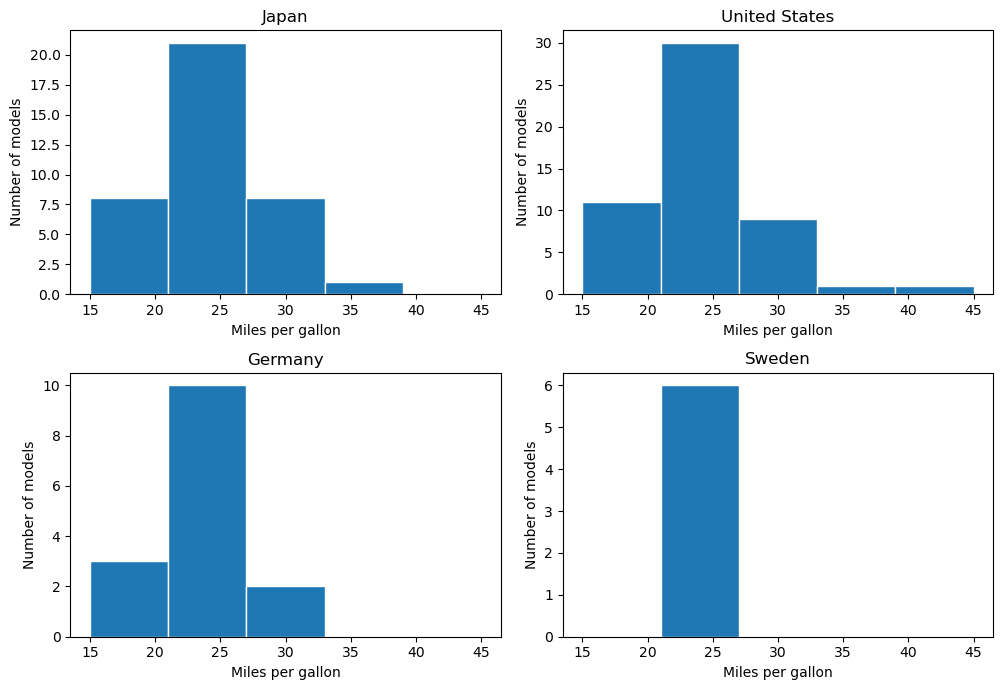

In [10]:
fig = plt.figure(figsize=(10, 7))
mpgRange = (df["mpg"].min(), df["mpg"].max())

for i, country in enumerate(countries):
    ax = fig.add_subplot(rows, 2, i + 1)
    mpg = df.loc[df["country"] == country, "mpg"].dropna()

    ax.hist(mpg, bins=5, range=mpgRange, edgecolor="white")
    ax.set_title(country)
    ax.set_xlabel("Miles per gallon")
    ax.set_ylabel("Number of models")

fig.tight_layout()
plt.show()

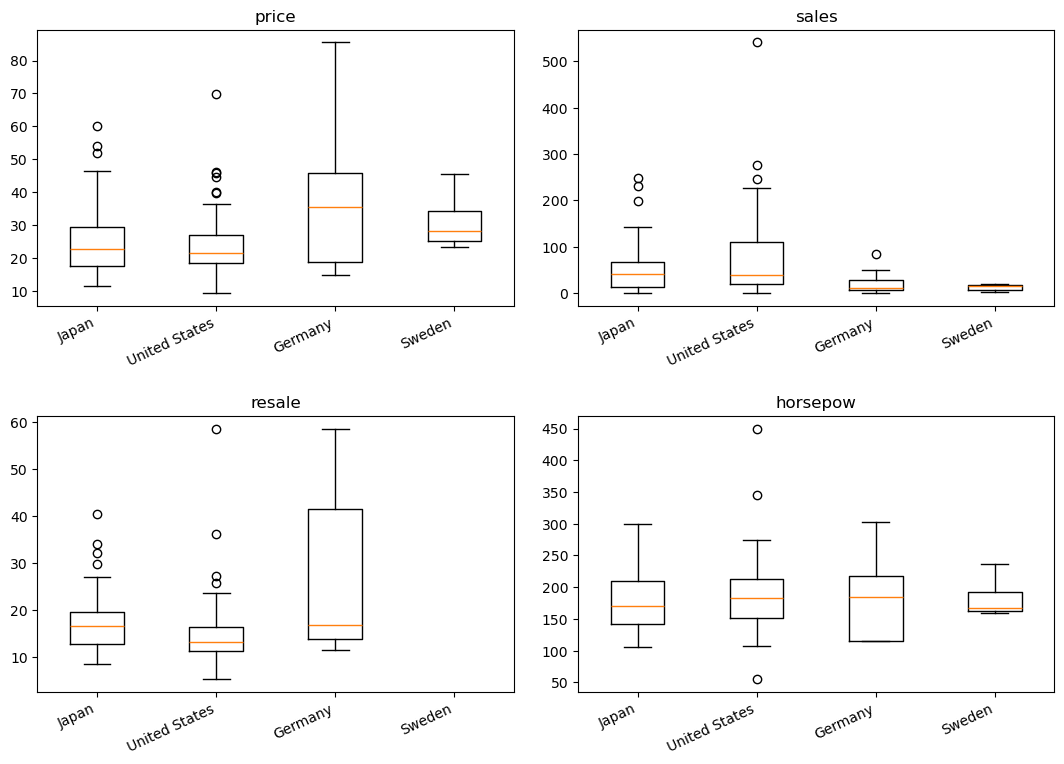

In [21]:
attributes = ["price", "sales", "resale", "horsepow"]

fig = plt.figure(figsize=(11, 8))

for i, attribute in enumerate(attributes):
    ax = fig.add_subplot(2, 2, i + 1)
    countryValues = []

    for country in countries:
        values = df.loc[df["country"] == country, attribute].dropna()
        countryValues.append(values)

    ax.boxplot(countryValues)
    ax.set_xticks(range(1, len(countries) + 1))
    ax.set_xticklabels(countries, rotation=25, ha="right")
    ax.set_title(attribute)

fig.tight_layout(pad=2)
plt.show()

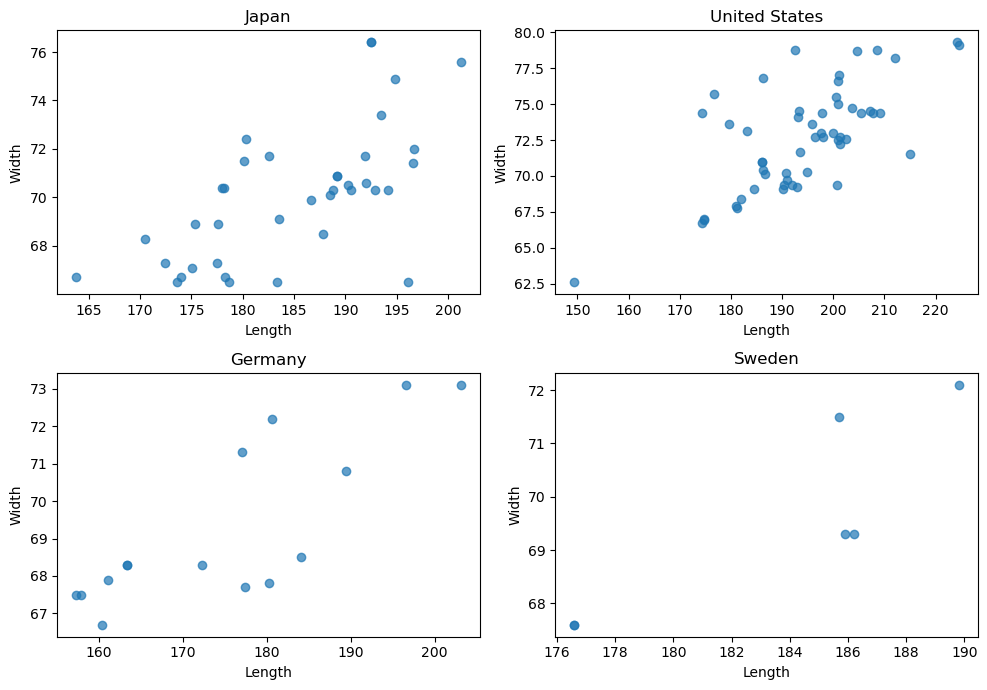

In [22]:
fig = plt.figure(figsize=(10, 7))

for i, country in enumerate(countries):
    ax = fig.add_subplot(rows, 2, i + 1)
    carGroup = df[df["country"] == country]

    ax.scatter(carGroup["length"], carGroup["width"], alpha=0.7)
    ax.set_title(country)
    ax.set_xlabel("Length")
    ax.set_ylabel("Width")

fig.tight_layout()
plt.show()

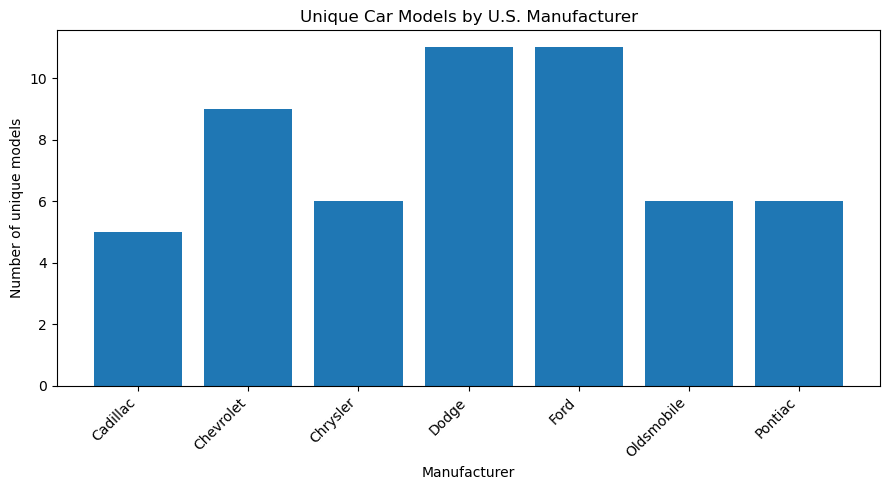

In [24]:
usCars = df[df["country"] == "United States"]
usCounts = usCars.groupby("manufact")["model"].nunique()

plt.figure(figsize=(9, 5))
plt.bar(usCounts.index, usCounts)
plt.title("Unique Car Models by U.S. Manufacturer")
plt.xlabel("Manufacturer")
plt.ylabel("Number of unique models")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

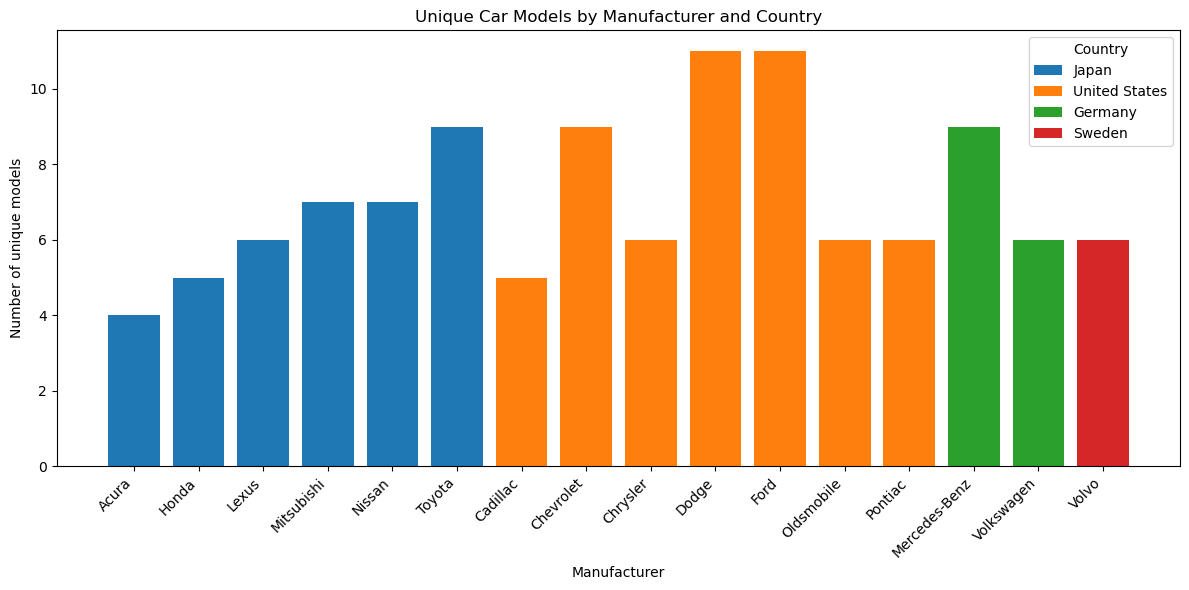

In [29]:
modelCounts = df.groupby(["country", "manufact"])["model"].nunique()

plt.figure(figsize=(12, 6))

for country in countries:
    counts = modelCounts.loc[country]
    plt.bar(counts.index, counts, label=country)

plt.title("Unique Car Models by Manufacturer and Country")
plt.xlabel("Manufacturer")
plt.ylabel("Number of unique models")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Country")
plt.tight_layout()
plt.show()

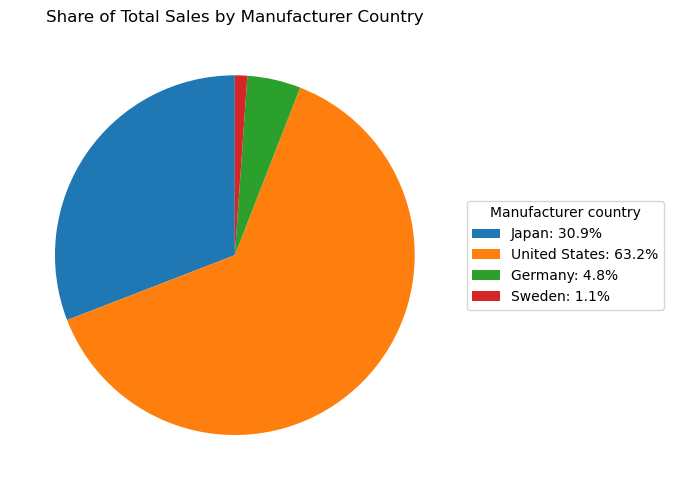

In [32]:
salesByCountry = df.groupby("country", sort=False)["sales"].sum()
salesShare = 100 * salesByCountry / salesByCountry.sum()

labels = []
for country in salesShare.index:
    labels.append(f"{country}: {salesShare[country]:.1f}%")

plt.figure(figsize=(8, 5))
plt.pie(salesByCountry, startangle=90)
plt.legend(
    labels,
    title="Manufacturer country",
    loc="center left",
    bbox_to_anchor=(1, 0.5)
)
plt.title("Share of Total Sales by Manufacturer Country")
plt.tight_layout()
plt.show()